In [17]:
from rliable import library as rly
from rliable import metrics
from rliable import plot_utils

In [18]:
# @title Imports

import collections
import numpy as np
import matplotlib.patches as patches
import sys
import pickle
import pandas as pd
import copy
import functools
import json
import os

import itertools as it
import random
import inspect
import scipy.stats

from pathlib import Path
import getpass
import os.path as osp

# See warnings only once
import warnings
warnings.filterwarnings('default')

# from google.colab import files
import inflection
from functools import partial

from typing import List, Dict, Any, Tuple, Union

# The answer to life, universe and everything
RAND_STATE = np.random.RandomState(42)

import logging
logger = logging.getLogger()
logger.setLevel(logging.INFO)

In [19]:
#@title Plotting: Seaborn style and matplotlib params
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
import seaborn as sns

sns.set_style("white")

# Matplotlib params
from matplotlib import rcParams
from matplotlib import rc

rcParams['legend.loc'] = 'best'
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

rc('text', usetex=False)

In [20]:
#@title Plotting Helpers
# from google.colab import files

# def save_fig(fig, name):
#   file_name = '{}.pdf'.format(name)
#   fig.savefig(file_name, format='pdf', bbox_inches='tight')
#   files.download(file_name)
#   return file_name

def set_axes(ax, xlim, ylim, xlabel, ylabel):
  ax.set_xlim(xlim)
  ax.set_ylim(ylim)
  ax.set_xlabel(xlabel, labelpad=14)
  ax.set_ylabel(ylabel, labelpad=14)

def set_ticks(ax, xticks, xticklabels, yticks, yticklabels):
  ax.set_xticks(xticks)
  ax.set_xticklabels(xticklabels)
  ax.set_yticks(yticks)
  ax.set_yticklabels(yticklabels)

def decorate_axis(ax, wrect=10, hrect=10, labelsize='large'):
  # Hide the right and top spines
  ax.spines['right'].set_visible(False)
  ax.spines['top'].set_visible(False)
  ax.spines['left'].set_linewidth(2)
  ax.spines['bottom'].set_linewidth(2)
  # Deal with ticks and the blank space at the origin
  ax.tick_params(length=0.1, width=0.1, labelsize=labelsize)
  # Pablos' comment
  ax.spines['left'].set_position(('outward', hrect))
  ax.spines['bottom'].set_position(('outward', wrect))

In [21]:
def load_metrics(file: Path):
    with open(file, 'rb') as f:
        metrics = pickle.load(f)
    return metrics

metrics_results = load_metrics('/home/andrea/workspaces/appl_ws/metrics.pickle')

def separate_metrics(results: pd.DataFrame) -> Tuple[Dict[str,pd.DataFrame]]:
    metrics_list = results.columns 
    metrics_list = [x for x in metrics_list if x not in ['experiment', 'algorithm', 'run']]
    metrics_dict = {}
    for metric in metrics_list:
        metrics_dict[metric] = results[[metric, 'algorithm', 'experiment', 'run']]
    return metrics_dict

In [22]:
metrics_results2 = metrics_results.copy()
metrics_results2['algorithm'] = 'DWB'
metrics_results2['experiment'] = 'passing'
for metric in metrics_results2.columns:
    # check if the metric is a float
    if metrics_results2[metric].dtype == 'float64':
        metrics_results2[metric] = metrics_results2[metric] + np.random.normal(0, 0.1, metrics_results2[metric].shape[0])

metrics_results = pd.concat([metrics_results, metrics_results2], ignore_index=True)
metrics_results2['algorithm'] = 'DWA'
metrics_results2['experiment'] = 'passing'
for metric in metrics_results2.columns:
    # check if the metric is a float
    if metrics_results2[metric].dtype == 'float64':
        metrics_results2[metric] = metrics_results2[metric] + np.random.normal(0, 0.1, metrics_results2[metric].shape[0])

metrics_results = pd.concat([metrics_results, metrics_results2], ignore_index=True)

metrics_results2['algorithm'] = 'DWB'
metrics_results2['experiment'] = 'overtaking'
for metric in metrics_results2.columns:
    # check if the metric is a float
    if metrics_results2[metric].dtype == 'float64':
        metrics_results2[metric] = metrics_results2[metric] + np.random.normal(0, 0.1, metrics_results2[metric].shape[0])

metrics_results = pd.concat([metrics_results, metrics_results2], ignore_index=True)

metrics_results2['algorithm'] = 'MPPI'
metrics_results2['experiment'] = 'overtaking'
for metric in metrics_results2.columns:
    # check if the metric is a float
    if metrics_results2[metric].dtype == 'float64':
        metrics_results2[metric] = metrics_results2[metric] + np.random.normal(1, 0.3, metrics_results2[metric].shape[0])

metrics_results = pd.concat([metrics_results, metrics_results2], ignore_index=True)

metrics_results2['algorithm'] = 'MPPI'
metrics_results2['experiment'] = 'passing'
for metric in metrics_results2.columns:
    # check if the metric is a float
    if metrics_results2[metric].dtype == 'float64':
        metrics_results2[metric] = metrics_results2[metric] + np.random.normal(1, 0.3, metrics_results2[metric].shape[0])

metrics_results = pd.concat([metrics_results, metrics_results2], ignore_index=True)
        

In [23]:
metrics_results

,time_to_reach_goal,path_length,cumulative_heading_changes,avg_distance_to_closest_person,minimum_distance_to_people,maximum_distance_to_people,intimate_space_intrusions,personal_space_intrusions,social_space_intrusions,public_space_intrusions,...,avg_closest_pedestrian_velocity,social_force_on_agents,social_force_on_robot,social_work,social_work_per_second,obstacle_force_on_agents,obstacle_force_on_robot,experiment,algorithm,run
0,18.199113,6.286400,15.873851,0.304108,-0.120790,1.546468,79.329609,15.083799,5.586592,0.000000,...,0.223080,45.769149,45.769149,25.559218,1.249982,0.073973,3.248989,overtaking,DWA,1
1,8.820175,4.768004,2.501649,0.166037,-0.121247,0.495390,75.119617,24.880383,0.000000,0.000000,...,0.354725,22.944122,22.944122,8.991859,0.671003,0.055478,0.372759,overtaking,DWA,2
2,11.380088,5.090755,3.280881,0.395293,0.158301,0.622699,36.475410,63.524590,0.000000,0.000000,...,0.264454,39.323577,39.323577,30.244754,2.336162,0.030185,2.672042,overtaking,DWA,3
3,15.220795,5.328096,17.093804,0.876782,0.111754,1.564305,23.101266,33.544304,43.354430,0.000000,...,0.169326,51.616333,51.616333,27.076016,1.442557,0.056079,9.258576,overtaking,DWA,4
4,11.673586,5.234213,3.219776,0.312451,0.027562,0.632455,65.503876,34.496124,0.000000,0.000000,...,0.242124,36.710676,36.710676,30.795905,2.329854,0.043098,2.131102,overtaking,DWA,5
5,18.220505,6.220475,15.889498,0.168805,-0.035290,1.493036,79.298307,15.061808,5.628239,0.137005,...,0.272659,45.935075,45.807779,25.574624,1.360366,0.300152,3.380400,passing,DWB,1
6,8.849059,4.776809,2.324052,0.168027,-0.233899,0.577911,74.928793,24.958059,0.102469,0.134263,...,0.468685,22.995348,23.021484,9.213618,0.693182,0.034427,0.307409,passing,DWB,2
7,11.434184,5.216883,3.394908,0.288947,0.167258,0.710448,36.394476,63.352397,-0.004873,-0.041291,...,0.430168,39.246202,39.151751,30.090980,2.448262,0.149705,2.564869,passing,DWB,3
8,15.347774,5.213388,17.328205,0.937703,0.096623,1.408702,22.987245,33.492220,43.243848,0.052977,...,0.159877,51.580344,51.576151,27.051335,1.453623,0.085037,9.343318,passing,DWB,4
9,11.687263,5.264770,3.067706,0.421519,-0.083367,0.680225,65.512355,34.610353,-0.139922,0.070170,...,0.380436,36.714742,36.656531,30.833003,2.403023,0.029273,2.158198,passing,DWB,5


In [24]:
#@title Helpers for normalizing scores and plotting histogram plots.
EXPERIMENTS = metrics_results['experiment'].unique()

def pgs(f):
  print(inspect.getsource(f))

def score_normalization(res_dict, min_scores, max_scores):
  experiments = res_dict.keys()
  norm_scores = {}
  for experiment, scores in res_dict.items():
    norm_scores[experiment] = (scores - min_scores[experiment])/(max_scores[experiment] - min_scores[experiment])
  return norm_scores


def convert_to_matrix(experiment_dict):
   keys = sorted(list(experiment_dict.keys()))
   return np.stack([experiment_dict[k] for k in keys], axis=1)

def plot_score_hist(score_matrix, bins=20, figsize=(28, 14),
                    fontsize='xx-large', N=6, extra_row=1,
                    names=None):
  print(score_matrix.shape)
  print(type(score_matrix))
  print(score_matrix)
  num_tasks = score_matrix.shape[1]
  if names is None:
    names = EXPERIMENTS
  N1 = (num_tasks // N) + extra_row
  fig, ax = plt.subplots(nrows=N1, ncols=N, figsize=figsize)
  for i in range(N):
    for j in range(N1):
      idx = j * N + i
      if idx < num_tasks:
        ax[j, i].set_title(names[idx], fontsize=fontsize)
        sns.histplot(score_matrix[:, idx], bins=bins, ax=ax[j,i], kde=True)
      else:
        ax[j, i].axis('off')
      decorate_axis(ax[j, i], wrect=5, hrect=5, labelsize='xx-large')
      ax[j, i].xaxis.set_major_locator(plt.MaxNLocator(4))
      if idx % N == 0:
        ax[j, i].set_ylabel('Count', size=fontsize)
      else:
        ax[j, i].yaxis.label.set_visible(False)
      ax[j, i].grid(axis='y', alpha=0.1)
  return fig

In [25]:
#@title Stratified Bootstrap CIs and Aggregate metrics

StratifiedBootstrap = rly.StratifiedBootstrap

IQM = lambda x: metrics.aggregate_iqm(x) # Interquartile Mean
OG = lambda x: metrics.aggregate_optimality_gap(x, 1.0) # Optimality Gap
MEAN = lambda x: metrics.aggregate_mean(x)
MEDIAN = lambda x: metrics.aggregate_median(x)

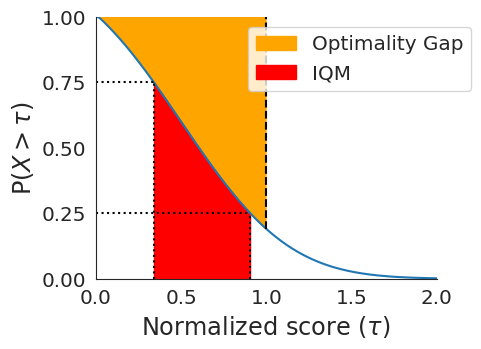

In [26]:
#@title Plot proposed aggregate metrics using performance profiles

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(4.4, 3.4))

mean, std = 0.5, 0.5
mult = 1.2
fn = lambda x: np.minimum(mult * (1 - scipy.stats.norm.cdf(x, loc=mean, scale=std)), 1.0)
inv_fn = lambda y: scipy.stats.norm.ppf(1 - (y / mult), loc=mean, scale=std)

x = np.linspace(0.0, 2.0 , 200)
y = fn(x)

ax.plot(x, y)


ax.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0])

ax.tick_params(labelsize='x-large')
ax.set_xlim(left=x[0], right=x[-1])
ax.set_ylim(0.0, 1.0)

y1 = y[(y>=0.25) & (y <=0.75)]
x1 = [a for a, t in zip(x, y) if (t <= 0.75) and (t >=0.25)]

ax.fill_between(x[x<=1], 1, y[x<=1], color='orange', label='Optimality Gap')

x_25, x_75 = inv_fn(0.75), inv_fn(0.25)


ax.axhline(y=0.25, xmax=x_75/x[-1], linestyle=":", color='black')
ax.axhline(y=0.75, xmax=x_25/x[-1], linestyle=":", color='black')
ax.axvline(x=1.0, ymin=fn(1.0), linestyle="--", color='black')

ax.axvline(x=x_25, ymax=0.75, linestyle=":", color='black')
ax.axvline(x=x_75, ymax=0.25, linestyle=":", color='black')
cond = (x >= x_25) & (x <= x_75)
ax.fill_between(x[cond], y[cond], 0.0, color='red',
                label='IQM')
ax.set_ylabel(r'P$(X > \tau)$', fontsize='xx-large')
ax.set_xlabel('Normalized score ' + r'$(\tau$)', fontsize='xx-large')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.legend(fontsize='x-large', loc='upper right',
           fancybox=True, bbox_to_anchor=(1.13, 1.0))
plt.show()

### Load Dataframe with all the data


In [27]:
#@title 

# def load_metrics(file: Path):
#     with open(file, 'rb') as f:
#         metrics = pickle.load(f)
#     return metrics

# metrics_results = load_metrics('/home/andrea/workspaces/appl_ws/metrics.pickle')

def separate_metrics(results: pd.DataFrame) -> Tuple[Dict[str,pd.DataFrame]]:
    metrics_list = results.columns 
    metrics_list = [x for x in metrics_list if x not in ['experiment', 'algorithm', 'run']]
    metrics_dict = {}
    for metric in metrics_list:
        metrics_dict[metric] = results[[metric, 'algorithm', 'experiment', 'run']]
    return metrics_dict

In [28]:
metrics_dict = separate_metrics(metrics_results)

for metric, df in metrics_dict.items():
    print(f'{metric}: {df.shape}')
    print(df.head())

time_to_reach_goal: (30, 4)
   time_to_reach_goal algorithm  experiment  run
0           18.199113       DWA  overtaking    1
1            8.820175       DWA  overtaking    2
2           11.380088       DWA  overtaking    3
3           15.220795       DWA  overtaking    4
4           11.673586       DWA  overtaking    5
path_length: (30, 4)
   path_length algorithm  experiment  run
0     6.286400       DWA  overtaking    1
1     4.768004       DWA  overtaking    2
2     5.090755       DWA  overtaking    3
3     5.328096       DWA  overtaking    4
4     5.234213       DWA  overtaking    5
cumulative_heading_changes: (30, 4)
   cumulative_heading_changes algorithm  experiment  run
0                   15.873851       DWA  overtaking    1
1                    2.501649       DWA  overtaking    2
2                    3.280881       DWA  overtaking    3
3                   17.093804       DWA  overtaking    4
4                    3.219776       DWA  overtaking    5
avg_distance_to_closest_per

In [29]:
#@title Score data for Human and random agent

RANDOM_SCORES = {}
HUMAN_SCORES = {}
for metric, df in metrics_dict.items():
  RANDOM_SCORES[metric] =  {}
  HUMAN_SCORES[metric] = {}
  for experiment in df['experiment'].unique():  
    # Random scores are obtained subtracting a random number from the minimum score
    RANDOM_SCORES[metric][experiment] = df[df['experiment'] == experiment][metric].min() - np.abs(np.random.randn())
    # Human scores are obtained adding a random number from the maximum score
    HUMAN_SCORES[metric][experiment] = df[df['experiment'] == experiment][metric].max() + np.abs(np.random.randn())
    

In [30]:
print(metrics_dict['path_length'])

    path_length algorithm  experiment  run
0      6.286400       DWA  overtaking    1
1      4.768004       DWA  overtaking    2
2      5.090755       DWA  overtaking    3
3      5.328096       DWA  overtaking    4
4      5.234213       DWA  overtaking    5
5      6.220475       DWB     passing    1
6      4.776809       DWB     passing    2
7      5.216883       DWB     passing    3
8      5.213388       DWB     passing    4
9      5.264770       DWB     passing    5
10     5.970342       DWA     passing    1
11     4.633588       DWA     passing    2
12     5.217299       DWA     passing    3
13     5.034769       DWA     passing    4
14     5.339321       DWA     passing    5
15     5.945699       DWB  overtaking    1
16     4.748578       DWB  overtaking    2
17     5.289792       DWB  overtaking    3
18     5.126398       DWB  overtaking    4
19     5.397589       DWB  overtaking    5
20     7.470725      MPPI  overtaking    1
21     5.802247      MPPI  overtaking    2
22     6.10

In [31]:
#@title Helpers for loading Atari 100k data

def create_metrics_dict_social_env(main_df, normalization=True,
                                 evaluation_key = 'eval_average_return'):
  """Creates a dictionary of scores."""
  metrics_dict = {}
  for key, df in main_df.items():
    metrics_dict[key] = df[evaluation_key].values
  if normalization:
    metrics_dict = score_normalization(metrics_dict, RANDOM_SCORES, HUMAN_SCORES)
  return metrics_dict


def load_metrics_normalized(algorithm_name, metric, metrics_dict):
  # print(f'Loading {metric} for {algorithm_name}:')
  df = metrics_dict[metric]
  normalized_metrics = {}
  for experiment in df['experiment'].unique():
    normalized_metrics[experiment] = df[(df['algorithm'] == algorithm_name) & (df['experiment'] == experiment)][metric].values
  normalized_metrics = score_normalization(normalized_metrics, RANDOM_SCORES[metric], HUMAN_SCORES[metric])
  normalized_metrics_matrix = convert_to_matrix(normalized_metrics)
  median, mean = MEDIAN(normalized_metrics_matrix), MEAN(normalized_metrics_matrix)
  # print('{}: Median: {}, Mean: {}'.format(metric, median, mean))
  return normalized_metrics, normalized_metrics_matrix


In [32]:
#@title Load all score dicts

path_length_dict_dwa, path_length_dwa  = load_metrics_normalized('DWA','path_length', metrics_dict)
path_length_dict_dwb, path_length_dwb  = load_metrics_normalized('DWB','path_length', metrics_dict)
path_length_dict_mppi, path_length_mppi  = load_metrics_normalized('MPPI','path_length', metrics_dict)

list_of_metrics = [metric for metric in metrics_dict.keys()]
print(list_of_metrics)
metrics_dict_dwa = {}
metrics_dict_dwb = {}
metrics_dict_mppi = {}
metrics_dwa = {}
metrics_dwb = {}
metrics_mppi = {}
for metric in list_of_metrics:
  metrics_dict_dwa[metric], metrics_dwa[metric] = load_metrics_normalized('DWA', metric, metrics_dict) 
  metrics_dict_dwb[metric], metrics_dwb[metric] = load_metrics_normalized('DWB', metric, metrics_dict)
  metrics_dict_mppi[metric], metrics_mppi[metric] = load_metrics_normalized('MPPI', metric, metrics_dict)
# score_data_dict = {'CURL': score_curl,
#                     'DrQ': score_drq,
#                     'DrQ(ε)': score_drq_eps,
#                     'DER': score_der,
#                     'SimPLe': score_simple,
#                     'OTR': score_otr,
#                     'SPR': score_spr}
metrics_data_dict = {}
path_length_data_dict = {'DWA': path_length_dwa, 'DWB': path_length_dwb, 'MPPI': path_length_mppi}
for metric in list_of_metrics:
  metrics_data_dict[metric] = {'DWA': metrics_dwa[metric], 'DWB': metrics_dwb[metric], 'MPPI': metrics_mppi[metric]}


['time_to_reach_goal', 'path_length', 'cumulative_heading_changes', 'avg_distance_to_closest_person', 'minimum_distance_to_people', 'maximum_distance_to_people', 'intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions', 'group_intimate_space_intrusions', 'group_personal_space_intrusions', 'group_social_space_intrusions', 'group_public_space_intrusions', 'robot_on_person_collision', 'person_on_robot_collision', 'time_not_moving', 'completed', 'final_goal_distance', 'minimum_goal_distance', 'avg_robot_linear_speed', 'avg_robot_angular_speed', 'avg_acceleration', 'avg_overacceleration', 'avg_pedestrian_velocity', 'avg_closest_pedestrian_velocity', 'social_force_on_agents', 'social_force_on_robot', 'social_work', 'social_work_per_second', 'obstacle_force_on_agents', 'obstacle_force_on_robot']


In [33]:
#@title Atari_100k Color setup
colors = sns.color_palette('colorblind')
# xlabels = ['DER', 'OTR', 'CURL', 'DrQ(ε)', 'SPR', 'SimPLe', 'DrQ']
xlabels = ['DWA', 'DWB', 'MPPI']

color_idxs = [0, 3, 4, 2, 1, 7, 8]
EXPERIMENTS_COLOR_DICT = dict(zip(xlabels, [colors[idx] for idx in color_idxs]))
experiments_metrics_dict = {}
experiments_path_length_dict = {}
for metric, val in metrics_data_dict.items():
  # print(f'{metric}:')
  for key, val in val.items():
    # print(f'{key}: {val[:10]}')
    experiments_metrics_dict[key] = val[:10]
for algorithm, val in path_length_data_dict.items():
  experiments_path_length_dict[algorithm] = val[:10]
colors

[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [34]:
#@title Score helpers -- Subsampling


def subsample_scores(metrics_dict, n=5, replace=False):
  subsampled_dict = {}
  total_samples = len(metrics_dict[list(metrics_dict.keys())[0]])
  for experiment, scores in metrics_dict.items():
    indices = np.random.choice(range(total_samples), size=n, replace=replace)
    subsampled_dict[experiment] = scores[indices]
  return subsampled_dict

def subsample_scores_mat(score_mat, num_samples=5, replace=False):
  subsampled_dict = []
  total_samples, num_experiments = score_mat.shape
  subsampled_scores = np.empty((num_samples, num_experiments))
  for i in range(num_experiments):
    indices = np.random.choice(total_samples, size=num_samples, replace=replace)
    subsampled_scores[:, i] = score_mat[indices, i]
  return subsampled_scores

def subsample_seeds(score_mat, num_samples=5, replace=False):
  indices = np.random.choice(
      score_mat.shape[0], size=num_samples, replace=replace)
  return score_mat[indices]

def batch_subsample_seeds(score_mat, num_samples=5, batch_size=100,
                          replace=False):
  indices = [
    np.random.choice(score_mat.shape[0], size=num_samples, replace=replace)
    for _ in range(batch_size)
  ]
  return (score_mat[idx] for idx in indices)

def subsample_scores_mat_with_replacement(score_mat, num_samples=5):
  subsampled_dict = []
  total_samples, num_experiments = score_mat.shape
  indices = np.random.choice(
      total_samples, size=(num_samples, num_experiments), replace=True)
  col_indices =  np.expand_dims(np.arange(num_experiments), axis=0)
  col_indices = np.repeat(col_indices, num_samples, axis=0)
  subsampled_scores = score_mat[indices, col_indices]
  return subsampled_scores

In [35]:
#@title Aggregate computation helpers

SIZES = [3, 5, 10, 25, 50, 100]

def calc_aggregate_fn(score_data, num_samples=5, total_n=20000,
                      aggregate_fn=MEDIAN, replace=False):
  subsampled_scores = batch_subsample_seeds(
      score_data, num_samples, batch_size=total_n, replace=replace)
  aggregates = [aggregate_fn(scores) for scores in subsampled_scores]
  return np.array(aggregates)

def calculate_aggregate_varying_sizes(score_matrix, aggregate_fn, total_n=20000,
                                      sizes=None, replace=False):
  agg_dict = {}
  if sizes is None:
    sizes = SIZES
  for size in sizes:
    agg_dict[n] = calc_aggregate_fn(score_matrix, num_samples=size, aggregate_fn=aggregate_fn,
                                    total_n=total_n, replace=replace)
    print('Mean Aggregate: {}'.format(np.mean(agg_dict[n])))
  return agg_dict

def CI(bootstrap_dist, stat_val=None, alpha=0.05, is_pivotal=False):
    """
    Get the bootstrap confidence interval for a given distribution.
    Args:
      bootstrap_distribution: numpy array of bootstrap results.
      stat_val: The overall statistic that this method is attempting to
        calculate error bars for. Default is None.
      alpha: The alpha value for the confidence intervals.
      is_pivotal: if true, use the pivotal (reverse percentile) method.
        If false, use the percentile method.
    Returns:
      (low, high): The lower and upper limit for `alpha` x 100% CIs.
      val: The median value of the bootstrap distribution if `stat_val` is None
        else `stat_val`.
    """
    # Adapted from https://pypi.org/project/bootstrapped
    if is_pivotal:
      assert stat_val is not None, 'Please pass the statistic for a pivotal'
      'confidence interval'
      low = 2 * stat_val - np.percentile(bootstrap_dist, 100 * (1 - alpha / 2.))
      val = stat_val
      high = 2 * stat_val - np.percentile(bootstrap_dist, 100 * (alpha / 2.))
    else:
      low = np.percentile(bootstrap_dist, 100 * (alpha / 2.))
      val = np.percentile(bootstrap_dist, 50)
      high = np.percentile(bootstrap_dist, 100 * (1 - alpha / 2.))
    return (low, high), val

INFO:absl:Calculating estimates for DWA ...
INFO:absl:Calculating estimates for DWB ...
INFO:absl:Calculating estimates for MPPI ...


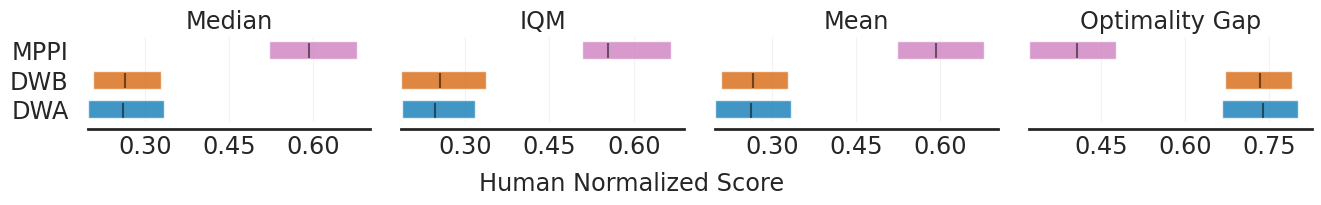

In [40]:
#@title Aggregates on Atari 100K (with 10 runs)


aggregate_func = lambda x: np.array([MEDIAN(x), IQM(x), MEAN(x), OG(x)])
aggregate_scores, aggregate_interval_estimates = rly.get_interval_estimates(
    experiments_path_length_dict, aggregate_func, reps=50000)

# algorithms = ['SimPLe', 'DER', 'OTR', 'CURL', 'DrQ', 'DrQ(ε)', 'SPR']
algorithms = ['DWA', 'DWB', 'MPPI']
fig, axes = plot_utils.plot_interval_estimates(
    aggregate_scores,
    aggregate_interval_estimates,
    metric_names = ['Median', 'IQM', 'Mean', 'Optimality Gap'],
    algorithms=algorithms,
    colors=EXPERIMENTS_COLOR_DICT,
    xlabel_y_coordinate=-0.5,
    xlabel='Human Normalized Score'
    )
plt.show()
# save_fig(fig, 'atari_100k_aggregates')

In [41]:
#@title DER Scores Distribution plots

# fig = plot_score_hist(path_length_dwa, bins=20, N=2, figsize=(26, 11))
# fig.subplots_adjust(hspace=0.85, wspace=0.17)
# plt.show()

In [42]:
from scipy.stats.stats import find_repeats
#@title Calculate score distributions and average score distributions for for Atari 100k

# algorithms = ['SimPLe', 'DER', 'OTR', 'CURL', 'DrQ(ε)', 'SPR']
algorithms = ['DWA', 'DWB', 'MPPI']
# score_dict = {key: score_data_dict[key][:10] for key in algorithms}
score_dict = {key: experiments_path_length_dict[key] for key in algorithms}
EXPERIMENTS_TAU = np.linspace(0.0, 2.0, 201)
# Higher value of reps corresponds to more accurate estimates but are slower
# to computed. `reps` corresponds to number of bootstrap resamples.
reps = 2000

score_distributions, score_distributions_cis = rly.create_performance_profile(
    score_dict, EXPERIMENTS_TAU, reps=reps)
avg_score_distributions, avg_score_distributions_cis = rly.create_performance_profile(
    score_dict, EXPERIMENTS_TAU, use_score_distribution=False, reps=reps)

/tmp/ipykernel_209877/3239250851.py:1: DeprecationWarning: Please import `find_repeats` from the `scipy.stats` namespace; the `scipy.stats.stats` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.stats.stats import find_repeats
INFO:absl:Calculating estimates for DWA ...
INFO:absl:Calculating estimates for DWB ...
INFO:absl:Calculating estimates for MPPI ...
INFO:absl:Calculating estimates for DWA ...
INFO:absl:Calculating estimates for DWB ...
INFO:absl:Calculating estimates for MPPI ...


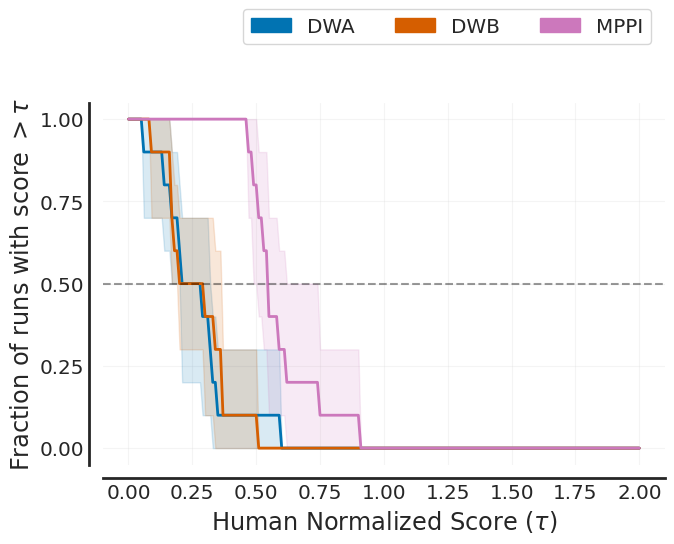

In [43]:
#@title Plot performance profiles (score distributions)

fig, ax = plt.subplots(ncols=1, figsize=(7.25, 4.7))

plot_utils.plot_performance_profiles(
  score_distributions, EXPERIMENTS_TAU,
  performance_profile_cis=score_distributions_cis,
  # colors=EXPERIMENTS_COLOR_DICT,
  colors=EXPERIMENTS_COLOR_DICT,
  xlabel=r'Human Normalized Score $(\tau)$',
  labelsize='xx-large',
  ax=ax)

ax.axhline(0.5, ls='--', color='k', alpha=0.4)
# fake_patches = [mpatches.Patch(color=EXPERIMENTS_COLOR_DICT[alg],
                              #  alpha=0.75) for alg in algorithms]
fake_patches = [mpatches.Patch(color=EXPERIMENTS_COLOR_DICT[alg],
                                label=alg) for alg in algorithms]
legend = fig.legend(fake_patches, algorithms, loc='upper center',
                    fancybox=True, ncol=len(algorithms),
                    fontsize='x-large',
                    bbox_to_anchor=(0.6, 1.1))

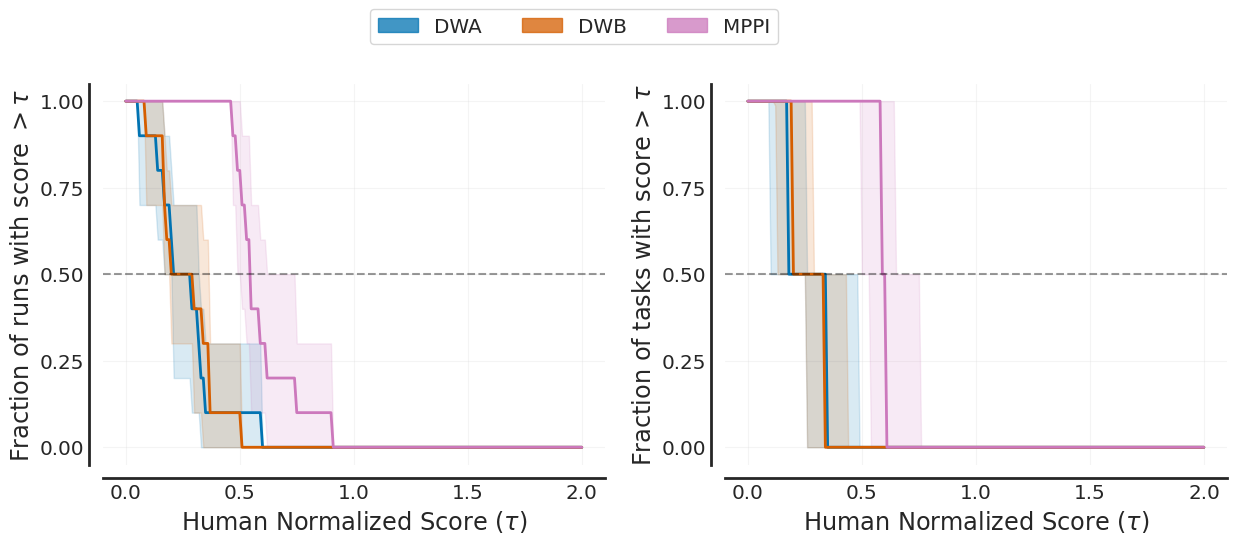

In [44]:
#@title Plot performance profiles (score distributions) and contrast with average score distribution
fig, axes = plt.subplots(ncols=2, figsize=(14.5, 4.7))

plot_utils.plot_performance_profiles(
  score_distributions, EXPERIMENTS_TAU,
  performance_profile_cis=score_distributions_cis,
  colors=EXPERIMENTS_COLOR_DICT,
  xlabel=r'Human Normalized Score $(\tau)$',
  labelsize='xx-large',
  ax=axes[0])


plot_utils.plot_performance_profiles(
  avg_score_distributions, EXPERIMENTS_TAU,
  performance_profile_cis=avg_score_distributions_cis,
  colors=EXPERIMENTS_COLOR_DICT,
  xlabel=r'Human Normalized Score $(\tau)$',
  ylabel=r'Fraction of tasks with score > $\tau$',
  labelsize='xx-large',
  ax=axes[1])

axes[0].axhline(0.5, ls='--', color='k', alpha=0.4)
axes[1].axhline(0.5, ls='--', color='k', alpha=0.4)

fake_patches = [mpatches.Patch(color=EXPERIMENTS_COLOR_DICT[alg],
                               alpha=0.75) for alg in algorithms]
legend = fig.legend(fake_patches, algorithms, loc='upper center',
                    fancybox=True, ncol=len(algorithms),
                    fontsize='x-large',
                    bbox_to_anchor=(0.45, 1.1))
fig.subplots_adjust(top=0.92, wspace=0.24)

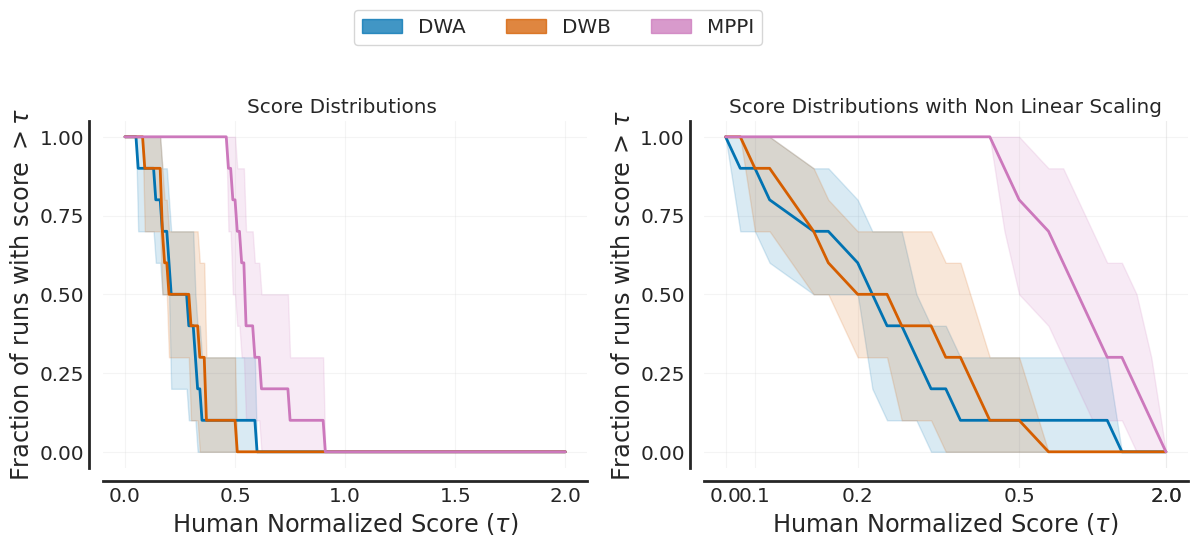

In [45]:
#@title Performance profiles for Atari 100K

fig, ax = plt.subplots(ncols=2, figsize=(7*2, 4.5))
# algorithms = ['SimPLe', 'DER', 'OTR', 'CURL', 'DrQ(ε)', 'SPR']
algorithms = ['DWA', 'DWB', 'MPPI']
plot_utils.plot_performance_profiles(
  score_distributions, EXPERIMENTS_TAU,
  performance_profile_cis=score_distributions_cis,
  colors=EXPERIMENTS_COLOR_DICT,
  xlabel=r'Human Normalized Score $(\tau)$',
  labelsize='xx-large',
  ax=ax[0])
ax[0].set_title('Score Distributions ', size='x-large')

xticks = [0.0, 0.1, 0.2, 0.5, 1.0, 2.0]
plot_utils.plot_performance_profiles(
  score_distributions, EXPERIMENTS_TAU,
  performance_profile_cis=score_distributions_cis,
  colors=EXPERIMENTS_COLOR_DICT,
  xlabel=r'Human Normalized Score $(\tau)$',
  ylabel=r'Fraction of runs with score > $\tau$',
  labelsize='xx-large',
  use_non_linear_scaling=True,
  xticks=xticks,
  ax=ax[1])
ax[1].set_title('Score Distributions with Non Linear Scaling', size='x-large')

fake_patches = [mpatches.Patch(color=EXPERIMENTS_COLOR_DICT[alg],
                               alpha=0.75) for alg in algorithms]
legend = fig.legend(fake_patches, algorithms, loc='upper center',
                    fancybox=True, ncol=len(algorithms),
                    fontsize='x-large',
                    bbox_to_anchor=(0.45, 1.15))
fig.subplots_adjust(wspace=0.24)

In [51]:
#@title Compute Probability of Improvement for all comparisons on Atari 100k

# algorithms = ['SimPLe', 'DER', 'OTR', 'CURL', 'DrQ(ε)', 'SPR']
algorithms = ['DWA', 'DWB','MPPI']
# our_algorithm = 'SPR' #@param ['SimPLe', 'DER', 'OTR', 'CURL', 'DrQ(ε)', 'SPR']
our_algorithm = 'MPPI'
all_pairs =  {}
for alg in (algorithms):
  if alg == our_algorithm:
    continue
  pair_name = f'{our_algorithm}_{alg}'
  all_pairs[pair_name] = (
      experiments_path_length_dict[our_algorithm], experiments_path_length_dict[alg])

probabilities, probability_cis = {}, {}
reps = 1000
probabilities, probability_cis = rly.get_interval_estimates(
    all_pairs, metrics.probability_of_improvement, reps=reps)

INFO:absl:Calculating estimates for MPPI_DWA ...
INFO:absl:Calculating estimates for MPPI_DWB ...


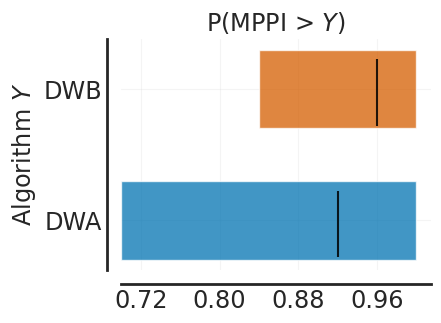

In [52]:
#@title Plot probabilities of improvement P(X > Y) with 95% CIs

fig, ax = plt.subplots(figsize=(4, 3))
h = 0.6
algorithm_labels = []

for i, (alg_pair, prob) in enumerate(probabilities.items()):
  _, alg1 = alg_pair.split('_')
  algorithm_labels.append(alg1)
  (l, u) = probability_cis[alg_pair]
  ax.barh(y=i, width=u-l, height=h,
          left=l, color=EXPERIMENTS_COLOR_DICT[alg1],
          alpha=0.75)
  ax.vlines(x=prob, ymin=i-7.5 * h/16, ymax=i+(6*h/16),
            color='k', alpha=0.85)
ax.set_yticks(range(len(algorithm_labels)))
ax.set_yticklabels(algorithm_labels)


ax.set_title(fr'P({our_algorithm} > $Y$)', size='xx-large')
plot_utils._annotate_and_decorate_axis(ax, labelsize='xx-large', ticklabelsize='xx-large')
ax.set_ylabel(r'Algorithm $Y$', size='xx-large')
ax.xaxis.set_major_locator(MaxNLocator(4))
fig.subplots_adjust(wspace=0.25, hspace=0.45)